# Лабораторная № 3: The Well — acoustic scattering maze

**Метод № 4: семплирование с отклонением. Критерий версии 3.**

Цель — выбрать структуру акустического уравнения по точности, сложности и
устойчивости к интервенциям. Используются симуляции The Well и аналитический
benchmark CNO/RPB, 2D + время. Физических измерений нет.

Постановка взята из предоставленной первой лабораторной Ф. Соболевского
(`vendor/lab1_sobolevsky.ipynb`). Её Python-модули не предоставлялись;
реализация самостоятельная. Bootstrap-диагностика адаптирована из лабораторной № 2.

Версия 3: E_int проверяет перенос на две отдельные траектории с фиксированными
коэффициентами. Эталоны берутся из сохранённых полей, а не из масштабирования
или обмена осей. Версии 1/2 сохранены в results/criterion_v1 и criterion_v2.
Bootstrap остаётся мягкой диагностикой, а J учитывает прямое решение PDE.

In [1]:
from pathlib import Path
import sys, os, json
PROJECT=Path.cwd()
if PROJECT.name=='lab03': PROJECT=PROJECT.parent
sys.path.insert(0,str(PROJECT))
os.environ['MPLCONFIGDIR']=str(PROJECT/'tmp/lab03/mpl')
import numpy as np
from IPython.display import display, Image
from lab03.model import ROOT,TERMS,bits,graph
from lab03.analytic import archive_audit
from lab03.run import run

def figure(name):display(Image(filename=str(ROOT/'figures'/f'{name}.png')))
print('Criterion configuration:')
display(json.loads((ROOT/'criterion.json').read_text()))


Criterion configuration:


{'version': 3,
 'moment_weight': 0.1,
 'pressure_weight': 1.0,
 'complexity_weight_per_branch': 0.02,
 'intervention_weight': 0.5,
 'bootstrap_weight': 0.01,
 'fresh_well_test_sample': 2,
 'fresh_analytic_test_seed': 55002,
 'validation_well_sample': 0,
 'validation_analytic_case': 1,
 'note': 'Frozen before new transfer trajectories are inspected and fresh test sample 2 / seed 55002 are evaluated. Weights unchanged from v2. Previous test samples 0 and 1 are development only.',
 'max_validation_pressure_error': 0.5,
 'transfer_well_samples': [1, 2],
 'transfer_analytic_seeds': [3104, 3106],
 'intervention_definition': 'Mean relative pressure L2 on two separately stored/generated trajectories; fixed fitted parameters, no scaled/transposed references.'}

## 1. Исходное уравнение и граф

$$p_t=-K(u_x+v_y),\qquad u_t=-\rho^{-1}p_x,\qquad v_t=-\rho^{-1}p_y.$$

Для статических $K,\rho$ исключение скорости даёт
$$p_{tt}=K\partial_x(\rho^{-1}p_x)+K\partial_y(\rho^{-1}p_y).$$
Плотность задаёт лабиринт; выносить её за производную нельзя. Известны
$p(0)=p_0$, $p_t(0)=0$. Решение интегрируется из этих условий.

Полная подбираемая модель:
$$\begin{aligned}
p_{tt}={}&\theta_1K\partial_x(\rho^{-1}p_x)+\theta_2K\partial_y(\rho^{-1}p_y)\\
&+\frac{\theta_3K}{2}[\partial_x(\rho^{-1}p_y)+\partial_y(\rho^{-1}p_x)]\\
&-\theta_4\frac{p_t}{T_0}-\theta_5\frac{p}{T_0^2}
-\theta_6\frac{p^3}{P_0^2T_0^2}.
\end{aligned}$$
Здесь $F_x=K\partial_x(\rho^{-1}p_x)$, $F_y=K\partial_y(\rho^{-1}p_y)$,
$F_{xy}=K[\partial_x(\rho^{-1}p_y)+\partial_y(\rho^{-1}p_x)]/2$,
$T_0=1$, $P_0=\max|p_{0,train}|$ фиксируется **по обучающей траектории**
и одинаков для валидации, переноса и теста. Это сохраняет физический смысл
коэффициента кубического члена между разными возбуждениями.

**Обратная задача:** подобрать структуру G и коэффициенты theta по наблюдениям.
Известные rho, K и начальное поле не оцениваются. theta1/theta2 задают потоки
по осям; theta3 — смешанный поток; theta4 — затухание; theta5 — линейный
возвращающий член; theta6 — кубическую нелинейность. Истинная структура имеет
theta=(1,1,0,0,0,0), но для поиска доступны все 64 варианта.
Разные возбуждения дают разные решения одного и того же уравнения.

Шесть переключателей дают 64 дерева выражений. Маска 3 — исходная структура,
63 — все члены. Коэффициенты подбираются только по обучению масштабированным
МНК/SVD. NetworkX хранит дерево и направленную матрицу смежности; одинаковые
операнды имеют отдельные вхождения, порядок аргументов сохраняется.

Динамическая структурная модель: $z_{n+1}=\Phi_G(z_n;\rho,K)+\epsilon_n$,
$z=(p,p_t)$. Временная развёртка ациклична. Физическое семейство задано заранее;
предпочтительность графа не доказывает причинность по произвольным наблюдениям.

In [2]:
import networkx as nx
g=graph(63)
print('Полный граф:',len(g),'вершин,',g.number_of_edges(),'рёбер')
print('DAG:',nx.is_directed_acyclic_graph(g))


Полный граф: 55 вершин, 54 рёбер
DAG: True


## 2. Данные и закрытая итоговая проверка

The Well, revision `8df383a3223f40f7ce66fe77b4ff4d7006dbc272`:
обучение — train/chunk_0/sample_0; валидация — valid/chunk_16/sample_0.
Берутся первые 101 кадр до t≈1.99, исходная сетка 256×256.
Фактические файлы имеют 202 кадра. Времена взяты из HDF5, физическая область
генератора — [-1,1]²; экспортные метки 0–1 не используются как физические центры.
Границы по метаданным и коду: нижние отражающие, верхние открытые на обеих осях.

Для нового E_int: **valid/chunk_16/sample_1 и sample_2**. Используются
их собственные начальные поля, карты rho/c и сохранённые будущие кадры.
Меняются и возбуждения, и геометрии; это совместный перенос, не изолированный
причинный эксперимент над амплитудой. theta и P0 при переносе фиксированы.

Прежние test/sample_0 и sample_1 уже просматривались и считаются разработочными.
После фиксации протокола в criterion.json новый итоговый тест —
**test/chunk_18/sample_2**. Веса J остались прежними.

CNO: опубликованные случаи 0/1 — обучение/валидация. В исходном архиве они
обозначены OOD; наше разделение учебное. Прежний случай 2 сохраняется для
проверки точной формулы. Новый окончательный тест — независимые коэффициенты
с зафиксированным seed **55002**, K=32, r=0.85. Это наша реализация опубликованного
семейства, а не дополнительная архивная запись. Для E_int — независимые
начальные поля seed 3104/3106, каждое со своей точной траекторией.

In [3]:
print('Published CNO endpoint audit:')
display(archive_audit())
for split,index in [('train',0),('valid',0),('valid',1),('valid',2)]:
    with np.load(ROOT/'data'/f'well_{split}_{index}.npz') as d:
        print(split,index,d['p'].shape,'time',float(d['t'][0]),float(d['t'][-1]))
with np.load(ROOT/'data/well_train_0.npz') as d:
    print('Actual initial pressure patch:')
    print(d['p'][0,78:81,226:229])


Published CNO endpoint audit:


[{'case': 0, 'endpoint_relative_error': 2.5850202892148277e-15},
 {'case': 1, 'endpoint_relative_error': 2.5206156501697778e-15},
 {'case': 2, 'endpoint_relative_error': 2.2659828111596323e-15}]

train 0 (101, 256, 256) time 0.0 1.9900497198104858
valid 0 (101, 256, 256) time 0.0 1.9900497198104858
valid 1 (101, 256, 256) time 0.0 1.9900497198104858
valid 2 (101, 256, 256) time 0.0 1.9900497198104858
Actual initial pressure patch:


[[4.5882382 5.073022  5.233427 ]
 [5.636234  5.78153   5.739513 ]
 [5.6414275 4.9808464 4.650961 ]]


## 3. Аналитический benchmark и оценка моментов

Полная модель, из которой выбирается структура в однородной среде:
$$\begin{aligned}
p_{tt}={}&c^2\theta_1p_{xx}+c^2\theta_2p_{yy}+c^2\theta_3p_{xy}\\
&-\theta_4\frac{p_t}{T_0}-\theta_5\frac{p}{T_0^2}
-\theta_6\frac{p^3}{P_0^2T_0^2},\qquad c=0.1.
\end{aligned}$$
Структура фиксирует исключённые коэффициенты в нуле; остальные подбираются
по обучению. Эталонные данные созданы при $\theta^*=(1,1,0,0,0,0)$.
Следующая формула задаёт **эталон при этих значениях**, а не произвольного кандидата:

$$p_*=\sum_{i,j=1}^{32}A_{ij}\sin(\pi ix)\sin(\pi jy)
\cos\left(0.1\pi t\sqrt{i^2+j^2}\right).$$
Коэффициенты опубликованных случаев восстановлены DST-I из поля на 64 узлах.
Поля сохраняют исходные амплитуды; min/max метаданные не применяются повторно.
Конечные архивные поля воспроизводятся до $3\cdot10^{-15}$.
Промежуточные кадры и производные — вычисления по формуле.

Для The Well используются приближённые слабые моменты: граневые потоки с
гармонической подвижностью, гауссово сглаживание (1.4 кадра, 2 ячейки),
производная временного ядра и исключение его краёв. Ошибка моментов
$E_m=\|X\hat\theta-y\|_2/\|y\|_2$ не равна ошибке давления.
На аналитике производные точные. Отдельно добавляется 1% коррелированного
шума только в обучающий $p_{tt}$: это вычислительное зашумление, не новая физика.

## 4. Bootstrap как диагностика, без запрета удаления

Сохраняется диагностика из лабораторной № 2: 1000 блочных реплик, блоки
4/8/12 полных кадров, 95%-е интервалы, повторный подбор при удалении ветви,
верхняя граница прироста ошибки моментов ≤0.01 и $W_1/SD_0\le1$ при условном
шуме остатков. Bootstrap-индексы базового и возмущённого опыта совпадают.

Пусть $b_j=1$, если прежнее консервативное правило советует сохранить ветвь.
Используем только ограниченный мягкий штраф
$$B(G)=\frac16\sum_{j\notin G}b_j\in[0,1].$$
Ненулевой интервал может отражать систематическую ошибку производных или
численную диссипацию. Поэтому он больше не обнуляет вероятность графа.
Интервалы условны на данной малой выборке; bootstrap не устраняет смещение.

## 5. Прямое решение на валидации и новый критерий

Все математически допустимые кандидаты решаются из начального поля:
The Well — Clawpack 5.9, unsplit MC, CFL 0.9; CNO — синусный Galerkin и DOP853.
Коэффициенты по-прежнему оцениваются только по обучению.

$$E_p(G)=\frac{\|p_G-p_{val}\|_2}{\|p_{val}\|_2},$$
$$J(G)=E_p(G)+0.1E_m(G)+0.02N(G)+0.5E_{int}(G)+0.01B(G).$$

$E_{int}$ теперь — средняя ошибка прямого решения на **двух других траекториях**:
$$E_{int}(G)=\frac12\sum_{k=1}^2
\frac{\|p_G^{(k)}-p_{ref}^{(k)}\|_2}{\|p_{ref}^{(k)}\|_2}.$$
Для The Well это valid/sample_1 и sample_2; для CNO — seed 3104 и 3106.
Коэффициенты взяты только из обучения и не переподбираются. Из каждой новой
траектории в солвер идут только начальное поле и свойства среды; будущие кадры
используются только для ошибки. Масштаб P0 остаётся обучающим.

Усиление амплитуды и транспонирование эталона исключены из J: они использовали
предположение о линейности/изотропии, а у линейных кандидатов амплитудная ошибка
повторяла базовую. Новые траектории независимы как реализации, но их всего две;
они не доказывают причинность и не являются физическими измерениями.

Жёсткие ограничения касаются пространственного тензора, возможности устойчиво
интегрировать модель и грубой ошибки давления **≤50% на валидации**.
Это не статистический запрет удаления. Для ускорения плохой кандидат можно
отклонить, когда уже накопленная сумма квадратов ошибок превышает 0.5² от
энергии всей эталонной траектории: будущие слагаемые неотрицательны.
Все веса и предел записаны до оценки новой тестовой траектории.

Кэш прямых расчётов содержит коэффициенты, ошибки, причины отказов и версию
солвера. Новый test/sample_2 и seed 55002 в этих расчётах не используются.

## 6. Как происходит семплирование с отклонением

Сэмплируется **структура**, не коэффициенты. Каждый бит маски включает одно
слагаемое; коэффициенты каждого кандидата заранее подобраны на обучении.
Оценки всех 64 графов кэшируются; повторное предложение не запускает PDE заново.

Одна попытка:
1. Независимо предложить любую маску 0..63 с равной вероятностью.
2. Проверить допустимость I(G). Недопустимый граф отклонить.
3. Для допустимого взять J и вычислить a=exp(-J/T).
4. Сгенерировать независимое U от 0 до 1. Принять, если U<=a.
5. Сохранить маску, U, результат и причину отказа; повторить.

При J=0.2, T=0.1 вероятность равна exp(-2)=0.1353. U=0.07 даёт принятие,
U=0.3 — отказ. Даже допустимый граф может быть случайно отклонён.
Предложения не являются локальными правками предыдущего графа.

В каждом раунде $q(G)=1/64$, независимо $U\sim\mathcal U(0,1)$.
Принимаем граф, если выполнены ограничения $I(G)=1$ и $U\le e^{-J(G)/T}$.
Поскольку $J\ge0$, ненормированная масса $q(G)I(G)e^{-J/T}\le q(G)$.
Следовательно,
$$P(G\mid accept)=\frac{q(G)I(G)e^{-J(G)/T}}
{\sum_Hq(H)I(H)e^{-J(H)/T}}.$$

Три раунда по 5000 предложений. Между раундами T уменьшается с учётом
квартиля принятых оценок; внутри раунда T и оценки фиксированы. Сохраняются
маски, U, принятия и причины отказов. Разные температуры не объединяются
для оценки одного стационарного распределения. Это мера качества, не posterior.

Малое семейство позволяет проверить распределение и минимум полным перебором.
Преимущество по скорости над перебором не заявляется. Семплирование за конечный
бюджет не гарантирует глобального оптимума вне этого семейства.

In [4]:
report=run(n_boot=1000)
from lab03.plotting import make_figures
make_figures()
print('Fresh test protocol:',report['evaluation'])


Inference well


well mask 3 parameters [1.00294362 1.00296136 0.         0.         0.         0.        ] test moments 0.03766638470313134


Inference analytic


analytic mask 3 parameters [1. 1. 0. 0. 0. 0.] test moments 9.018902365646755e-16


Inference analytic_noise


analytic_noise mask 3 parameters [1.00011438 0.99995313 0.         0.         0.         0.        ] test moments 6.255741793827079e-05


... (2 outputs left out)

selected {'relative_L2': 0.5737270712852478, 'lowpass_relative_L2': 0.20430270405429252, 'final_relative_L2': 0.7151668667793274, 'steps': 950}


Completed in 7.974379292019876 seconds


Scientific figures generated


Fresh test protocol: {'well_test_sample': 2, 'analytic_test_seed': 55002, 'well_transfer_samples': [1, 2], 'analytic_transfer_seeds': [3104, 3106], 'old_well_tests': [0, 1], 'old_analytic_tests': [55001], 'note': 'Old tests are development only; new tests are not used in graph selection'}


## 7. Основная валидация и перенос на другие траектории

Сравнение исходной структуры (3) и структуры с затуханием (11) использует одинаковые данные и Clawpack. Обе структуры теперь допустимы; bootstrap даёт только небольшой штраф.

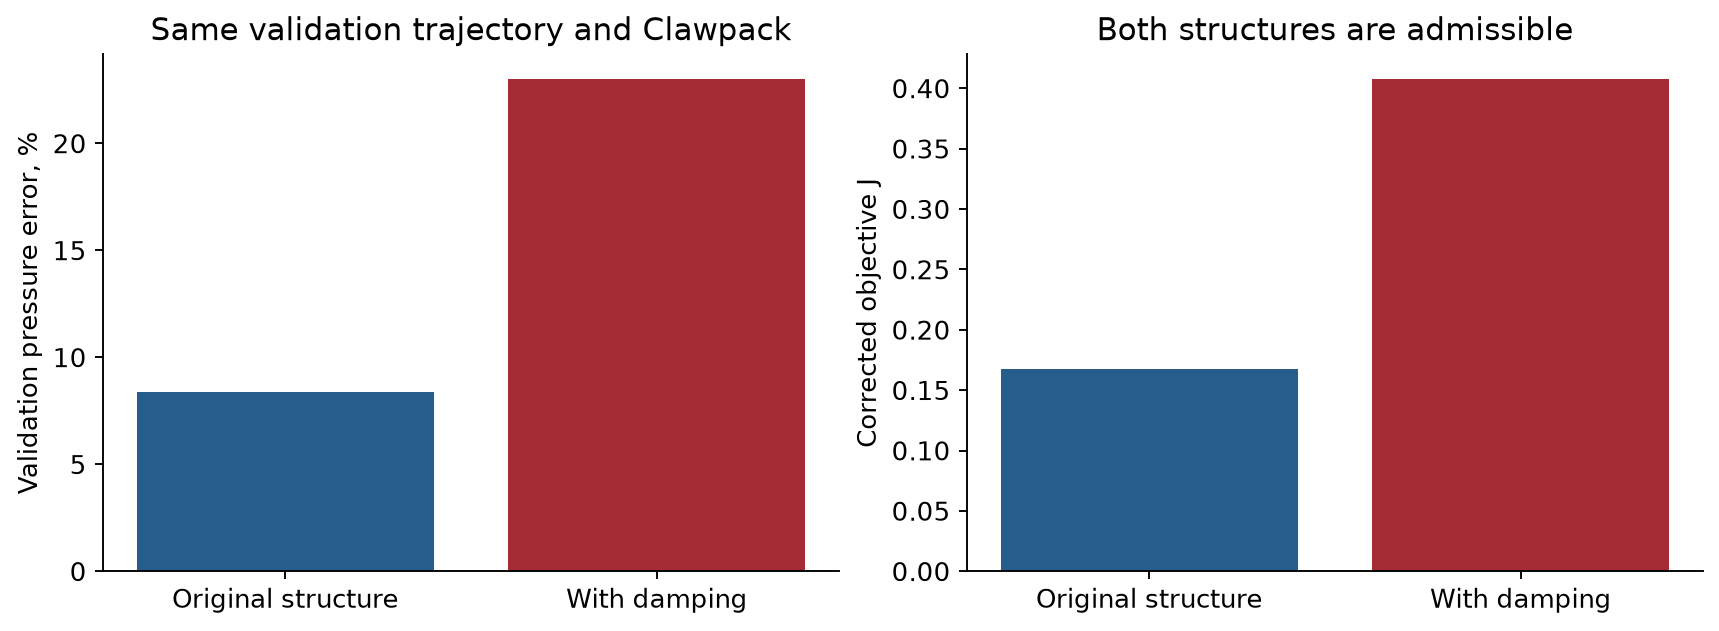

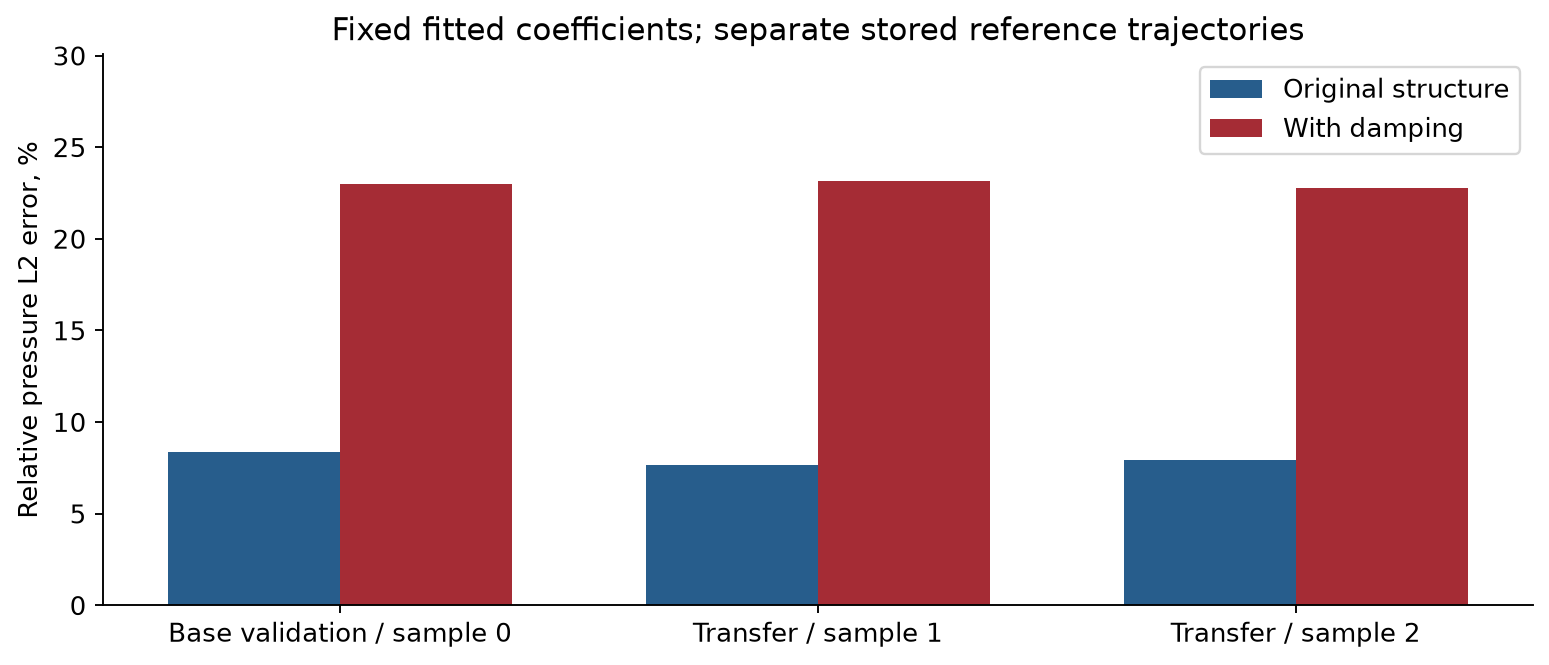

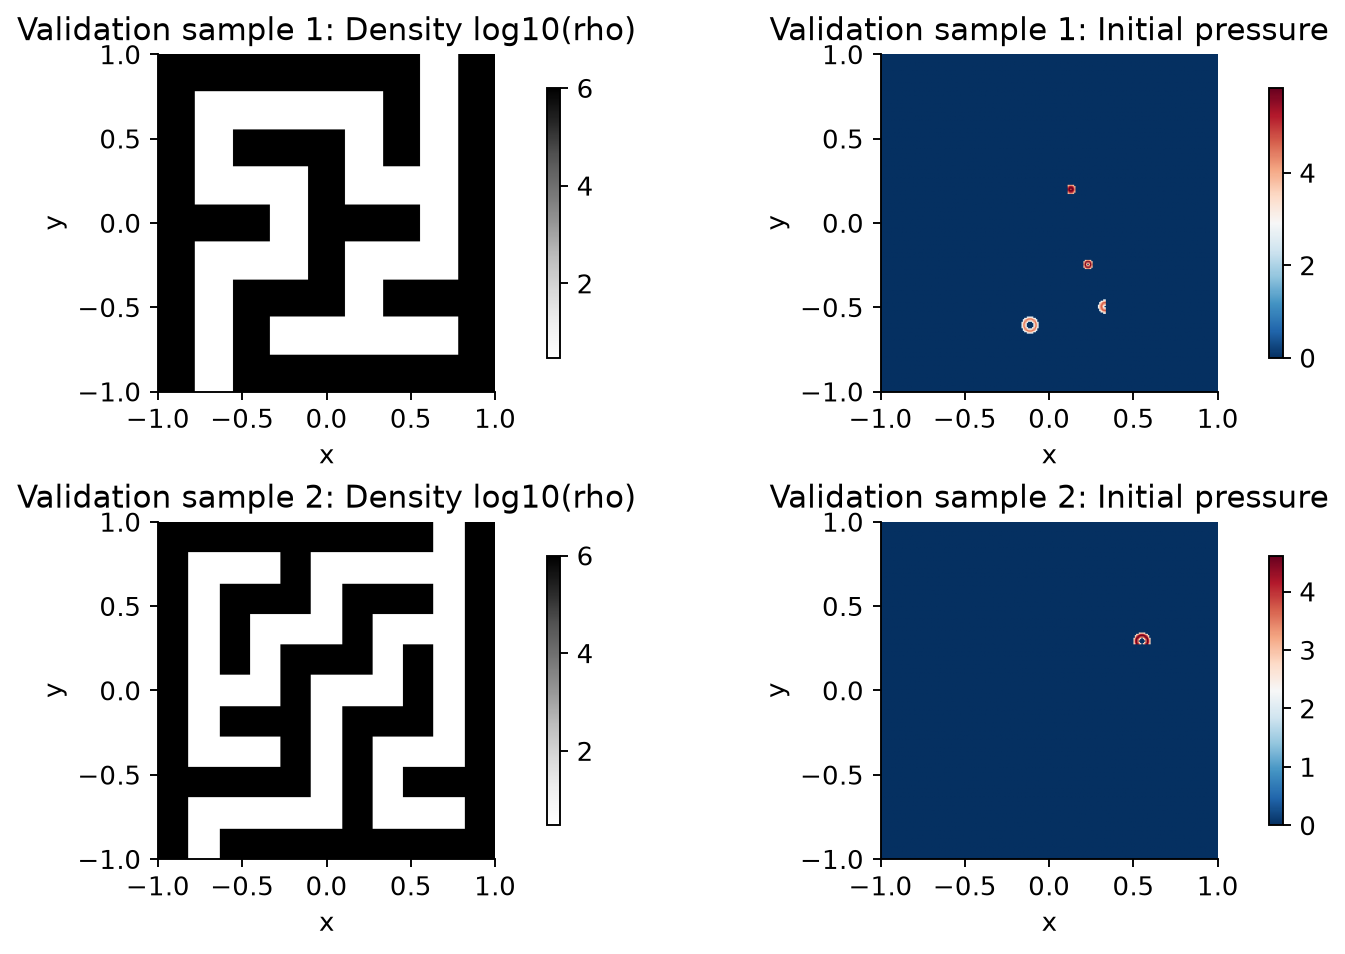

Mask 3 allowed: True pressure validation: 0.08367436332212405 transfer pressure: 0.0778316037764562 bootstrap risk: 0.16666666666666666 J: 0.1671199428846292
Mask 11 allowed: True pressure validation: 0.23010320218443234 transfer pressure: 0.22953098377078354 bootstrap risk: 0.0 J: 0.40776629085616345


In [5]:
figure('criterion_comparison')
figure('transfer_errors')
figure('transfer_data')
rows=json.loads((ROOT/'results/well_catalog.json').read_text())
for mask in (3,11):
    q=rows[mask]
    print('Mask',mask,'allowed:',q['gate'],'pressure validation:',q['validation_pressure'],
          'transfer pressure:',q['intervention_pressure'],'bootstrap risk:',q['bootstrap_risk'],'J:',q['J'])


## 8. Последовательности и проверка распределения

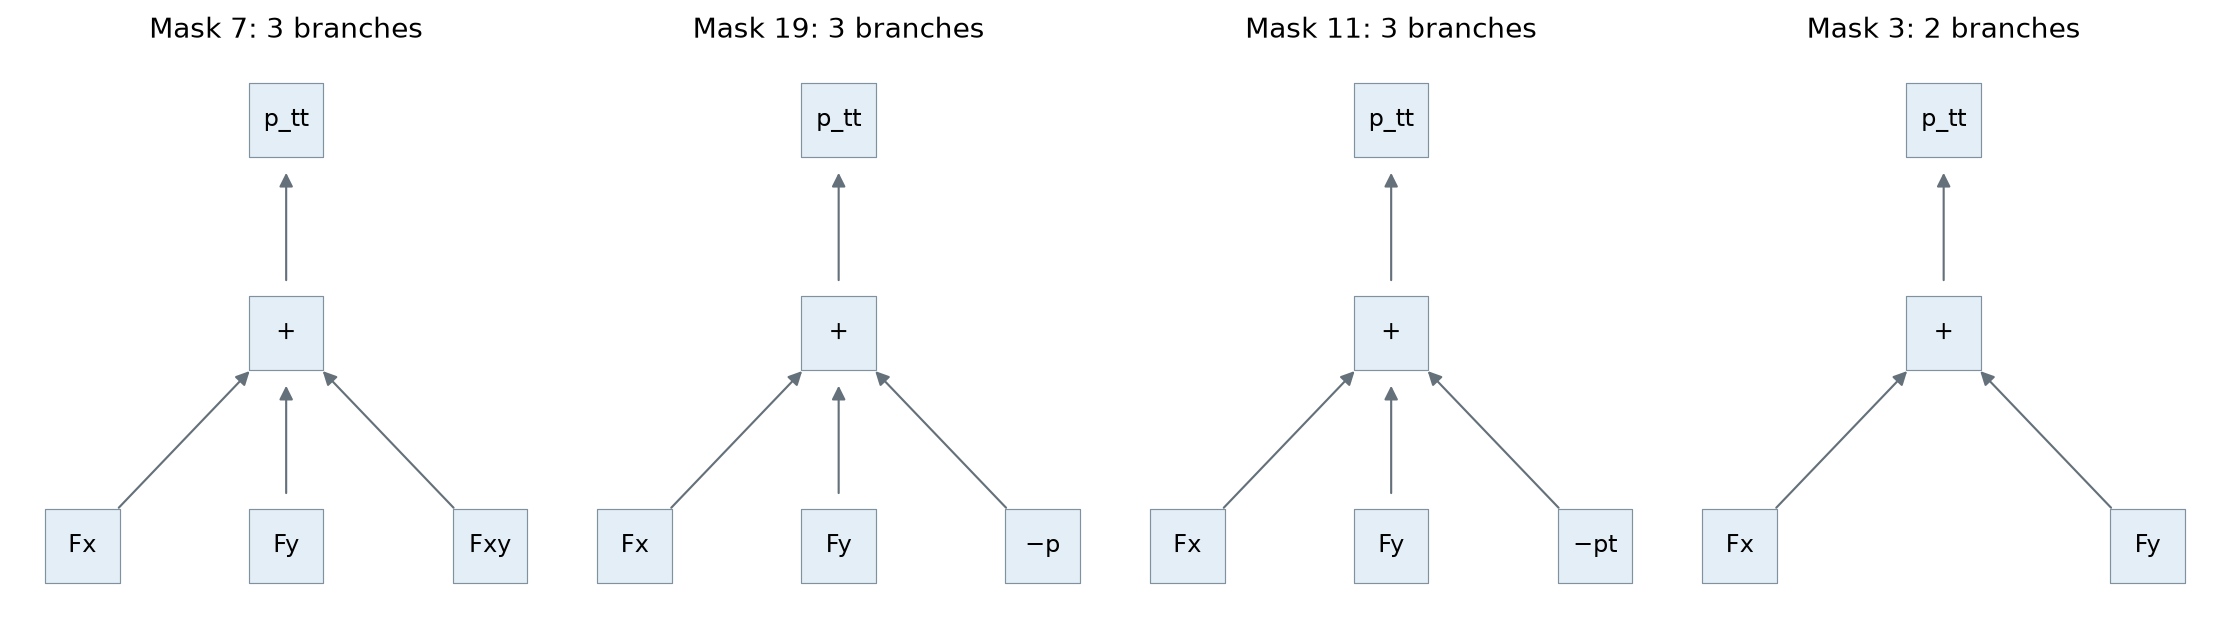

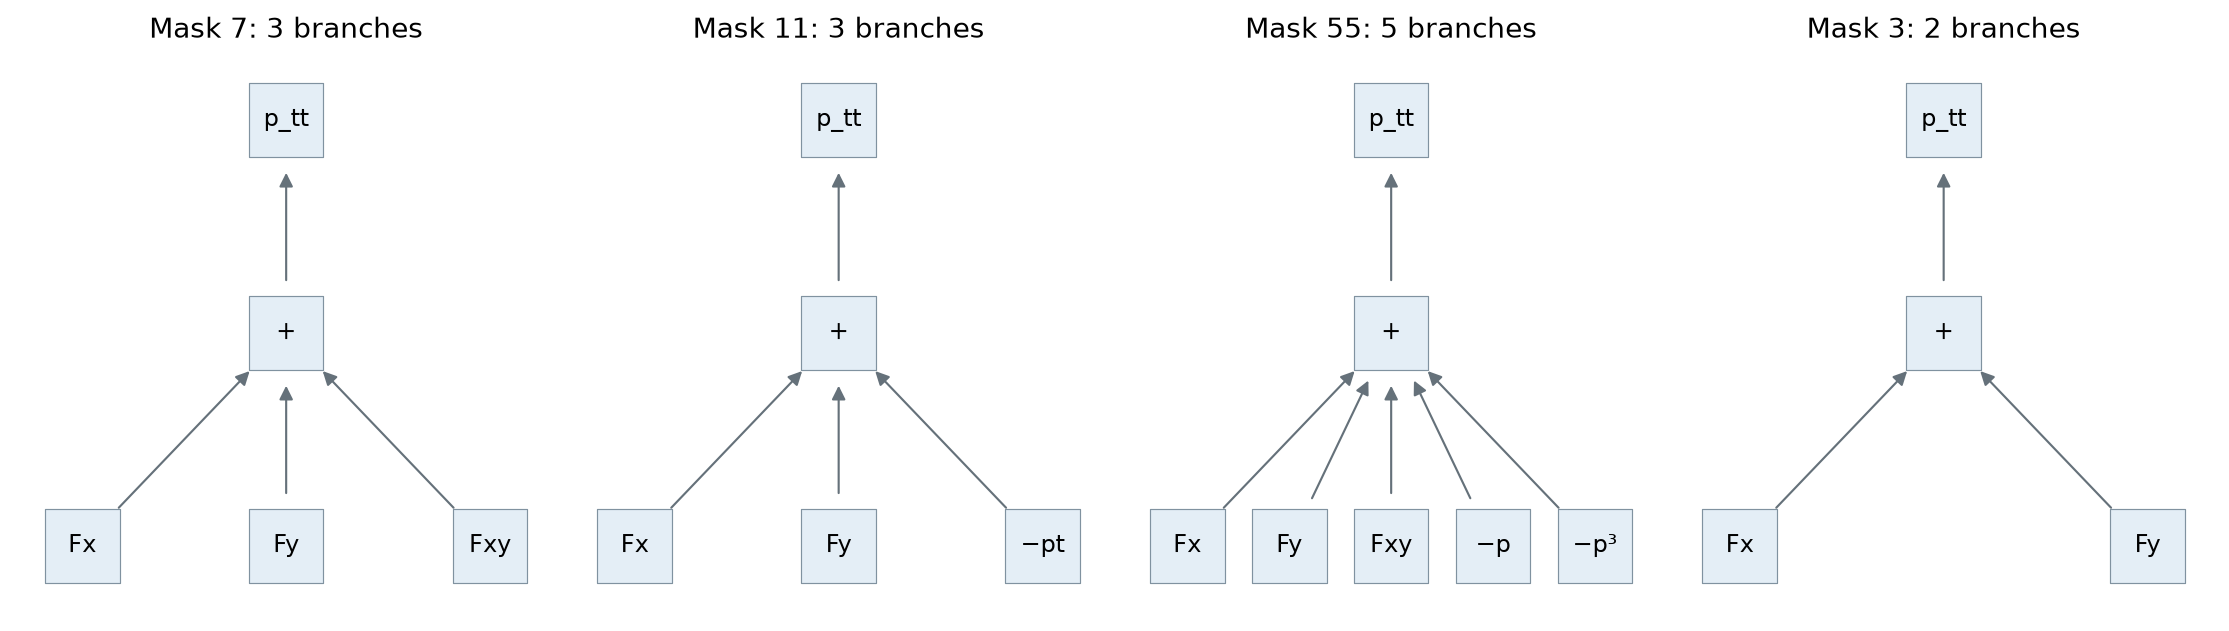

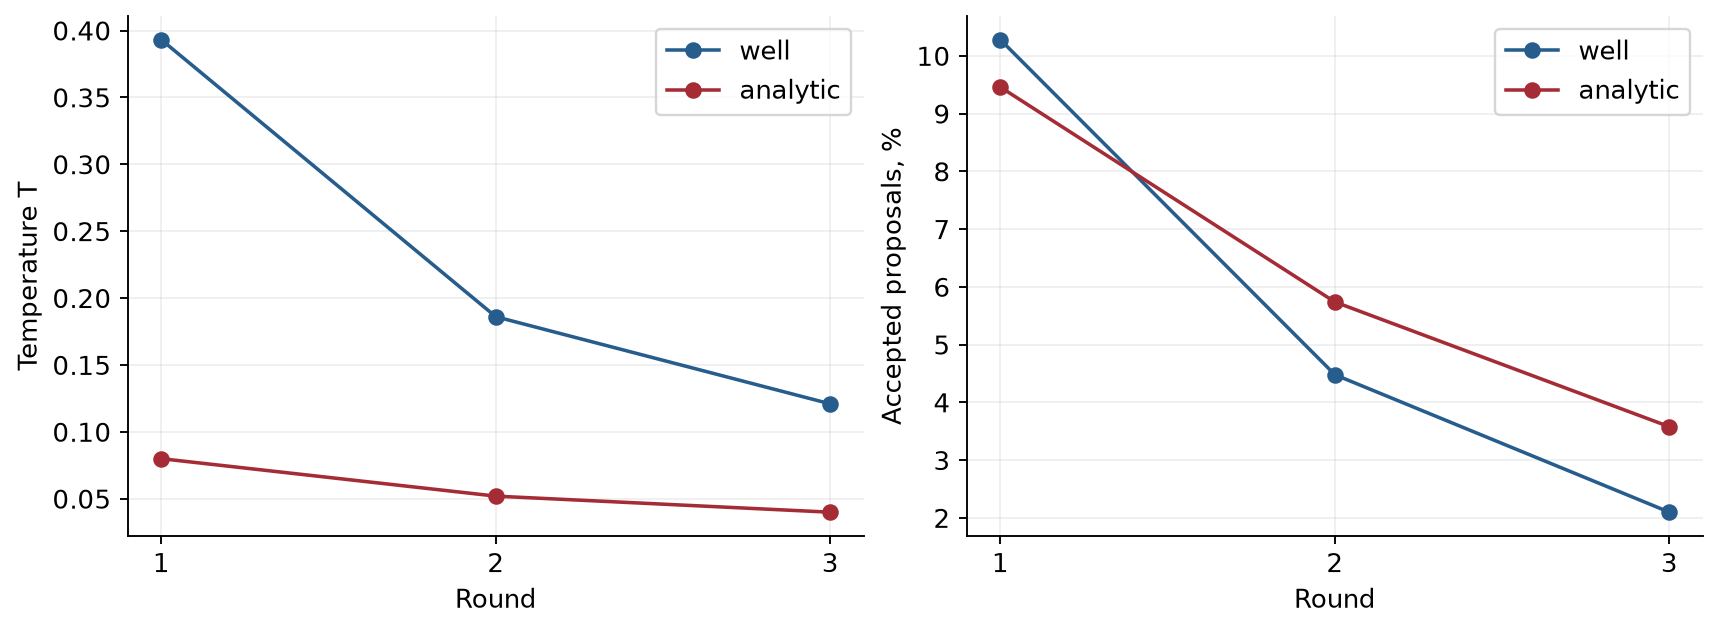

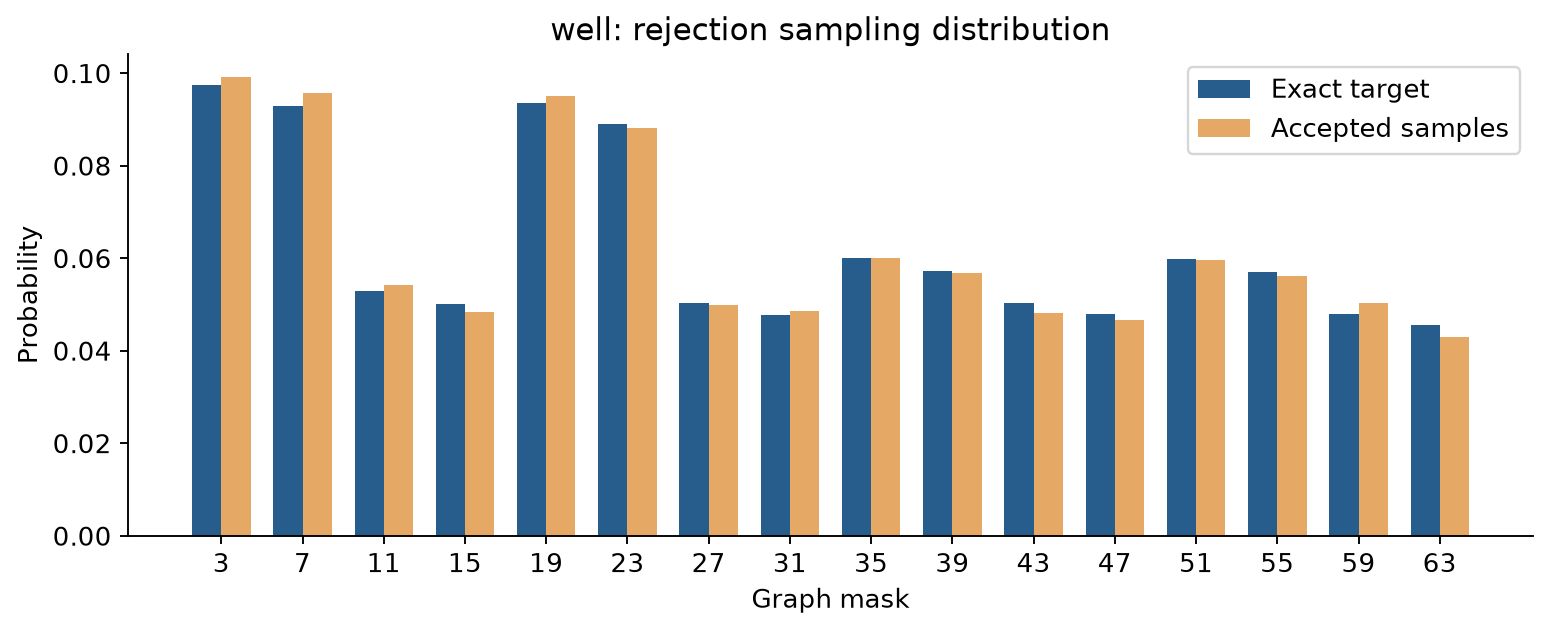

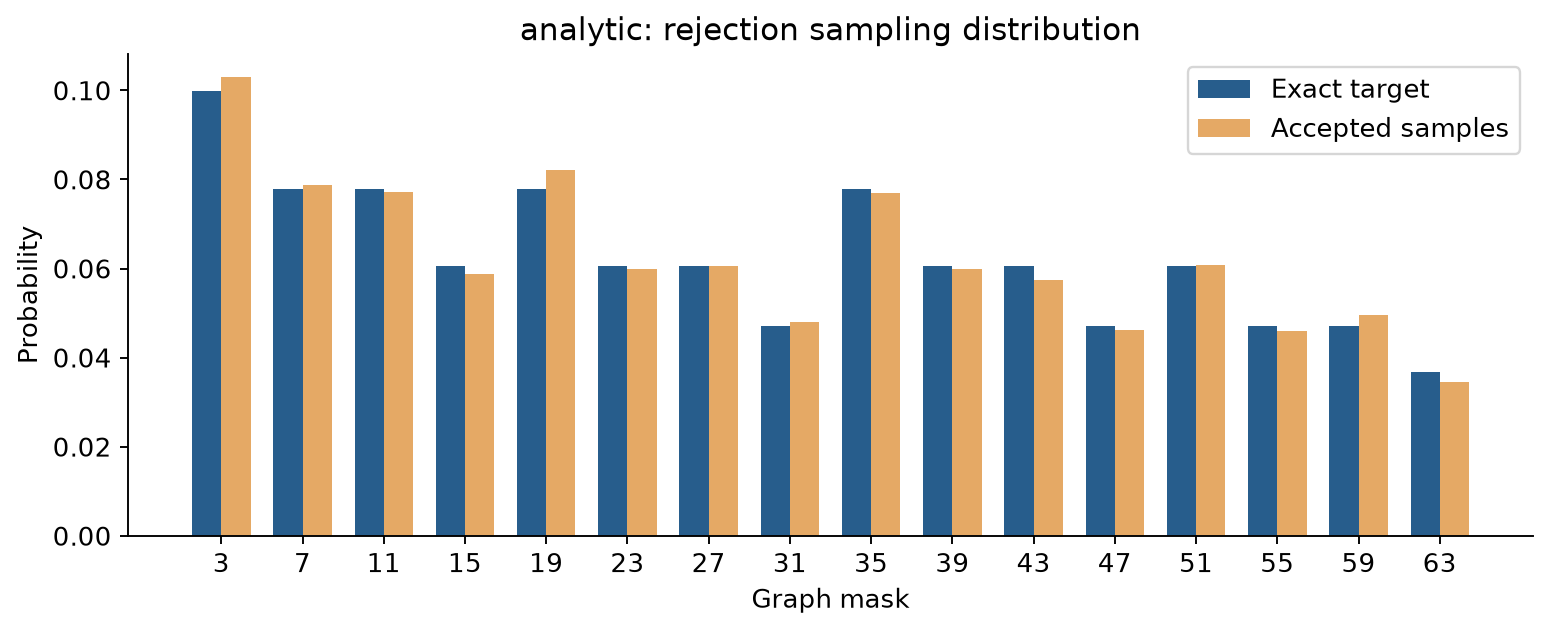

well TV: 0.010592561170837667 exhaustive best: 3
analytic TV: 0.01215431516472415 exhaustive best: 3
analytic_noise TV: 0.013178895362518426 exhaustive best: 3


In [6]:
figure('well_sequence')
figure('analytic_sequence')
figure('sampling_rounds')
figure('well_distribution')
figure('analytic_distribution')
for name in ('well','analytic','analytic_noise'):
    c=report[name]['comparison']
    print(name,'TV:',c['audit_TV'],'exhaustive best:',c['exhaustive_best_under_gate'])


## 9. Выбранные деревья и матрицы смежности

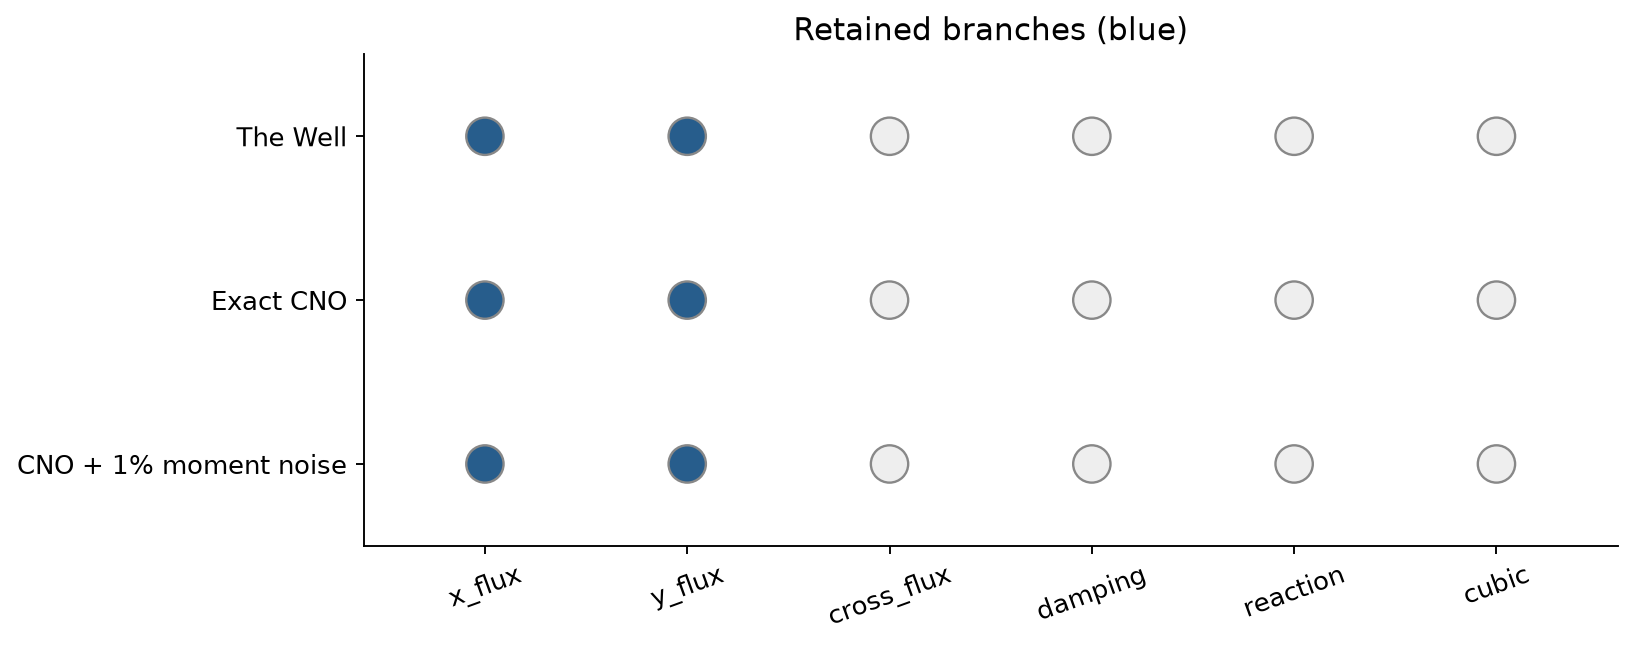

well mask: 3 theta: [1.00294362 1.00296136 0.         0.         0.         0.        ] fresh test moment error: 0.03766638470313134
analytic mask: 3 theta: [1. 1. 0. 0. 0. 0.] fresh test moment error: 9.018902365646755e-16
analytic_noise mask: 3 theta: [1.00011438 0.99995313 0.         0.         0.         0.        ] fresh test moment error: 6.255741793827079e-05


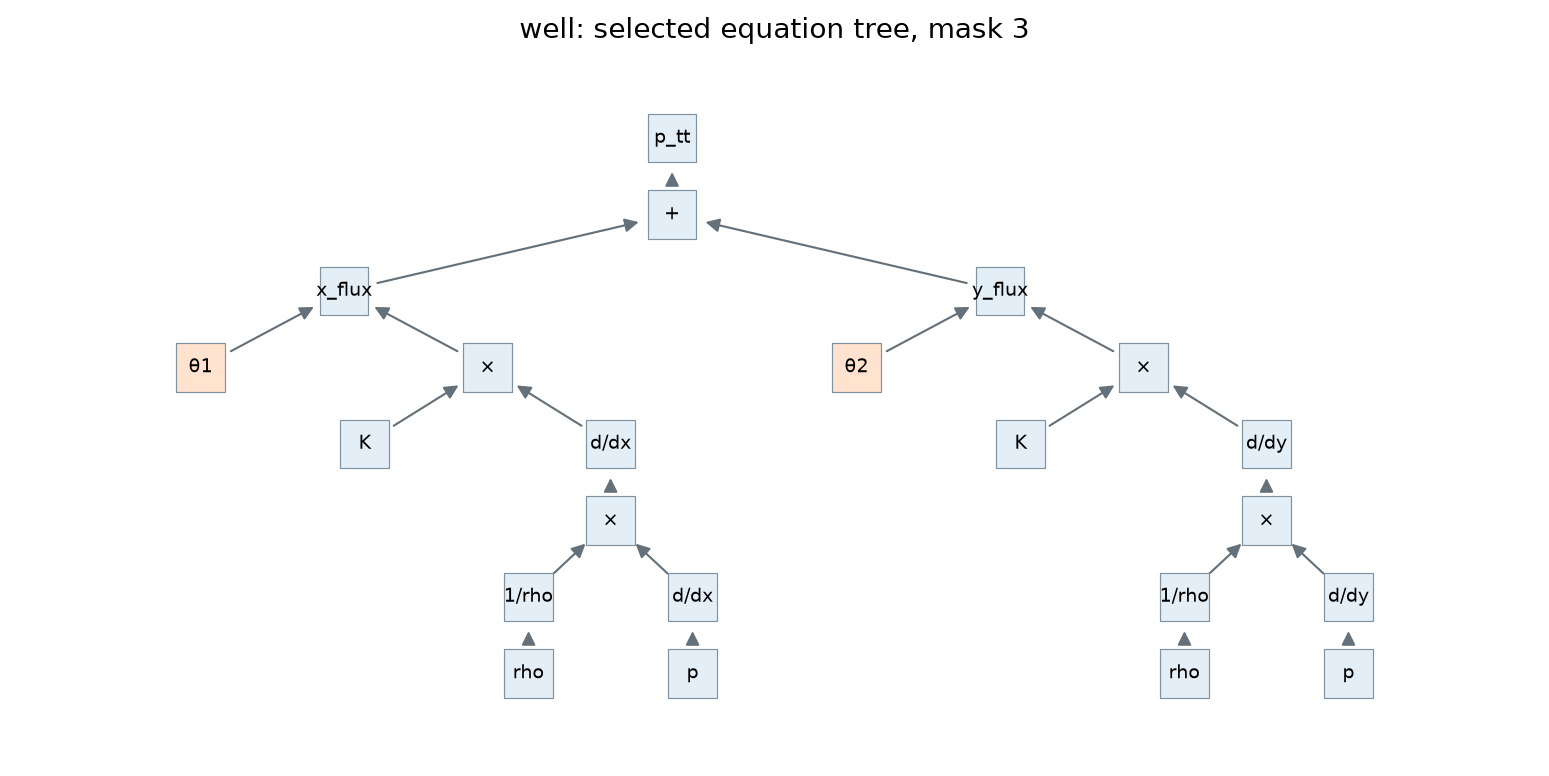

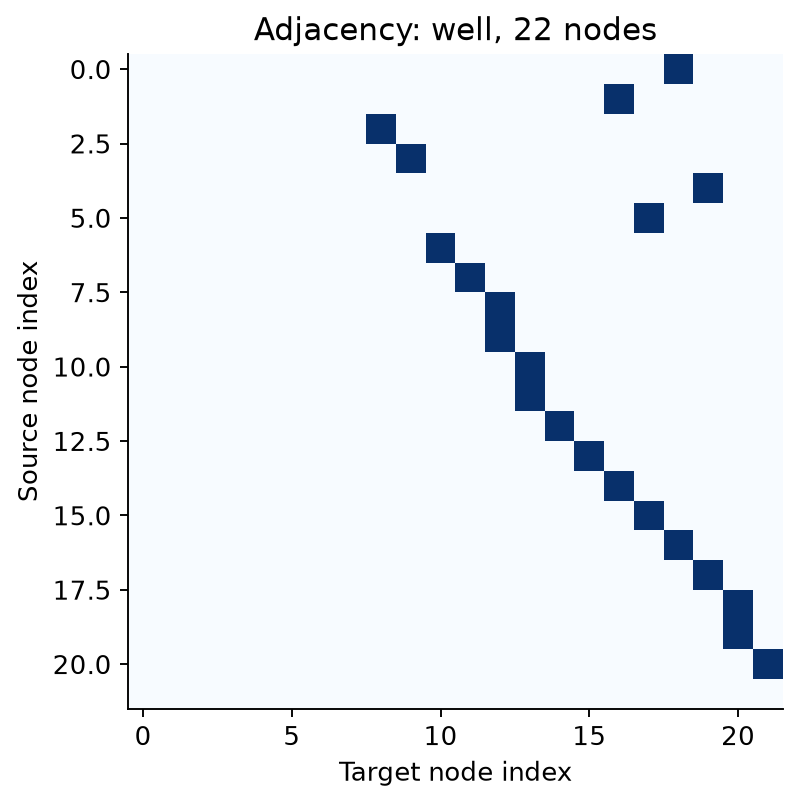

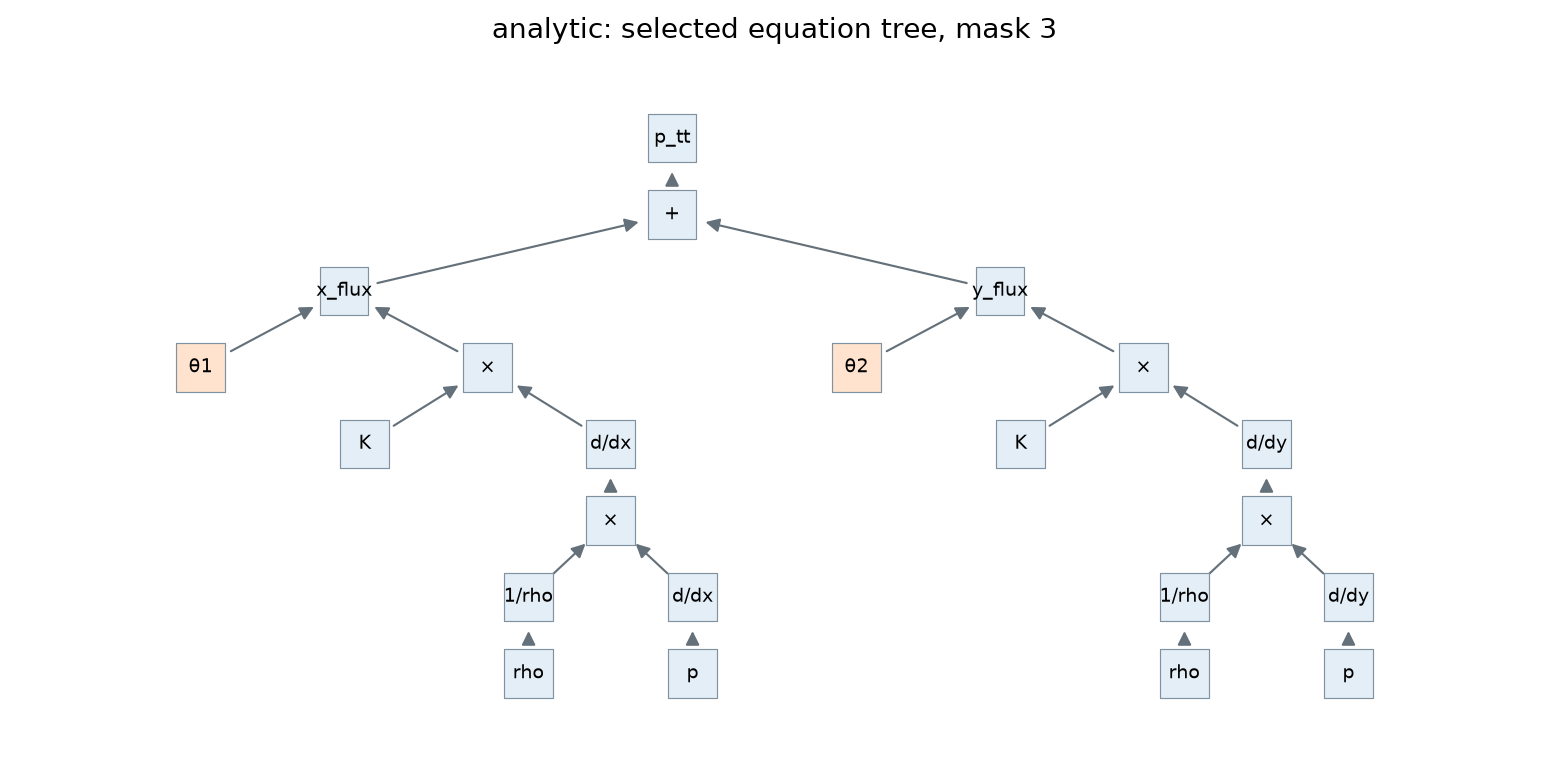

In [7]:
figure('selected_branches')
for name in ('well','analytic','analytic_noise'):
    s=report[name]['selected']
    print(name,'mask:',s['mask'],'theta:',np.round(s['parameters'],8),
          'fresh test moment error:',s['test_moment_error'])
figure('well_tree')
figure('well_adjacency')
figure('analytic_tree')


## 10. Окончательная проверка на новых данных

Тест проводится после фиксации графа. Последующие кадры не подаются в солвер. Для The Well приводится Clawpack; независимая центральная схема остаётся проверкой чувствительности к дискретизации. Аналитическая задача интегрируется спектральным Galerkin + DOP853 и сравнивается с точной формулой.

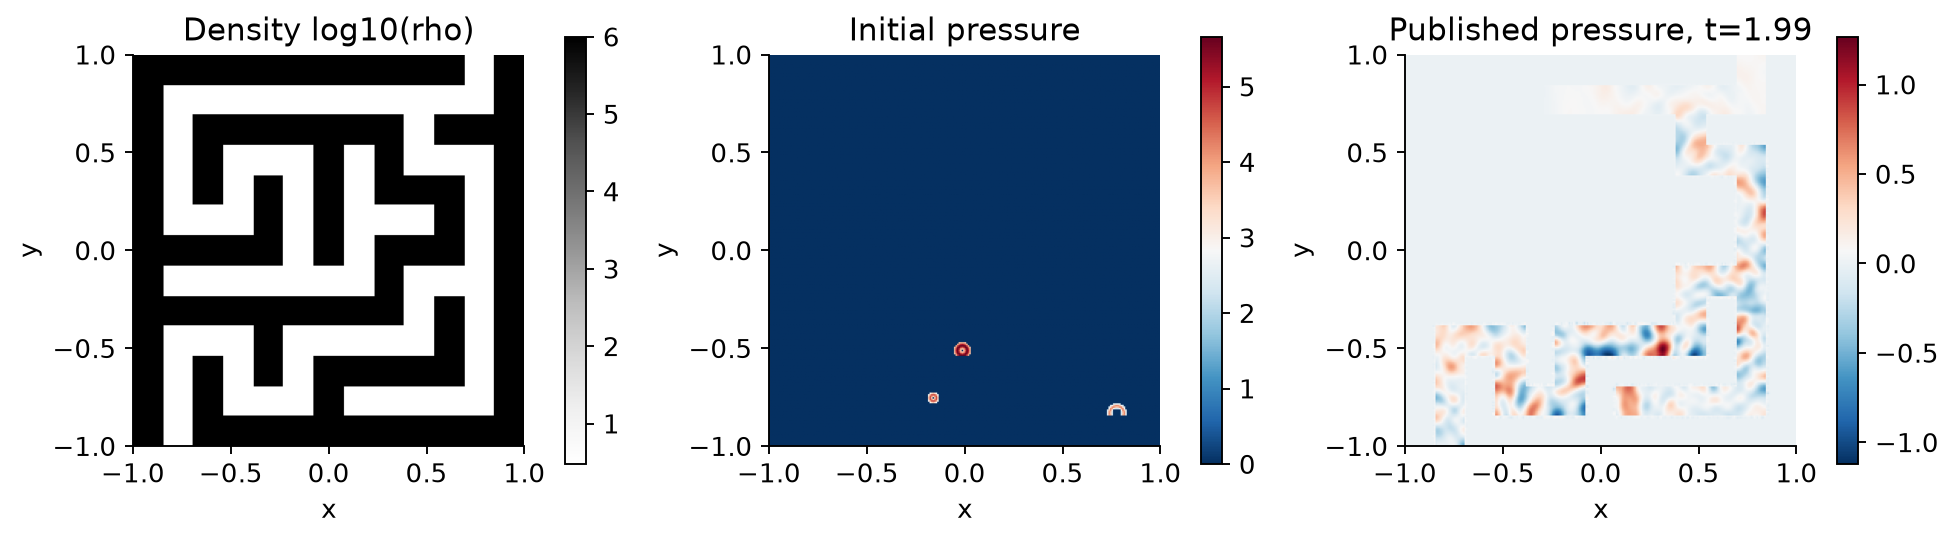

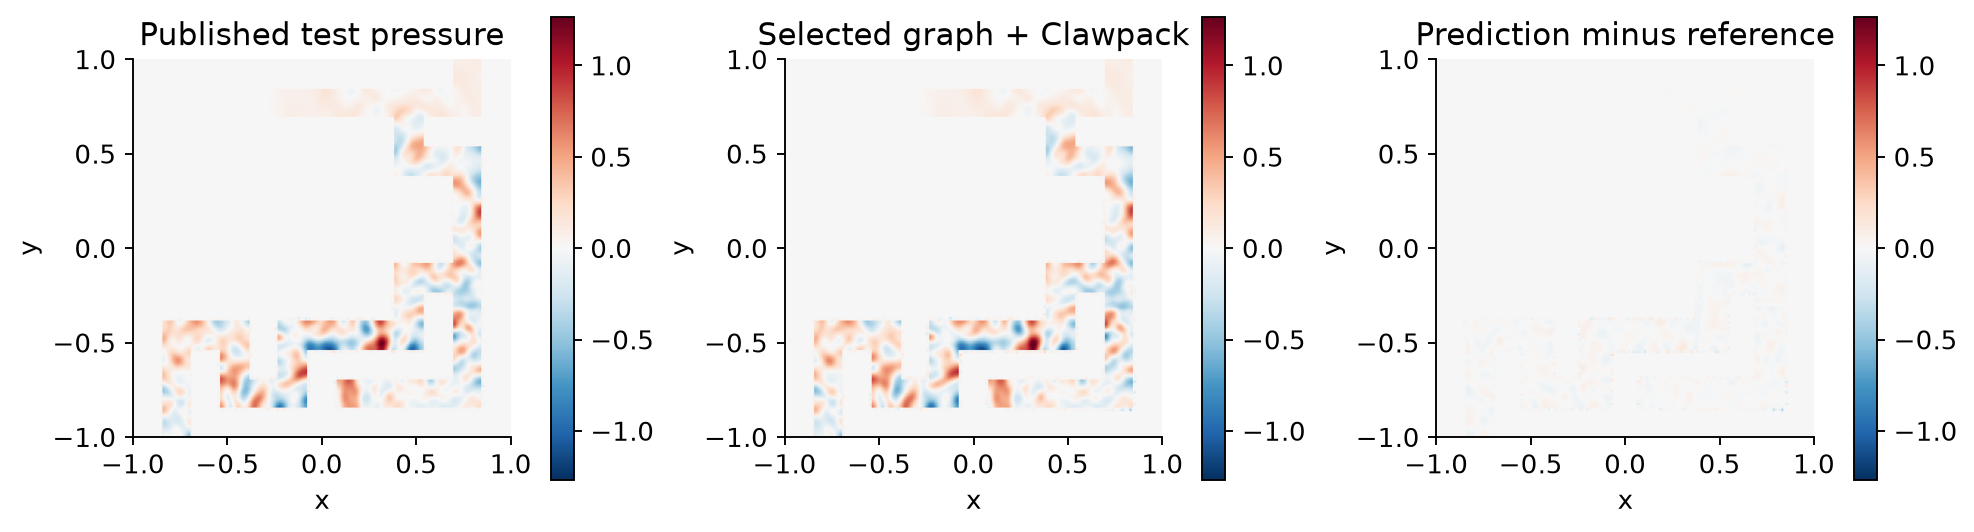

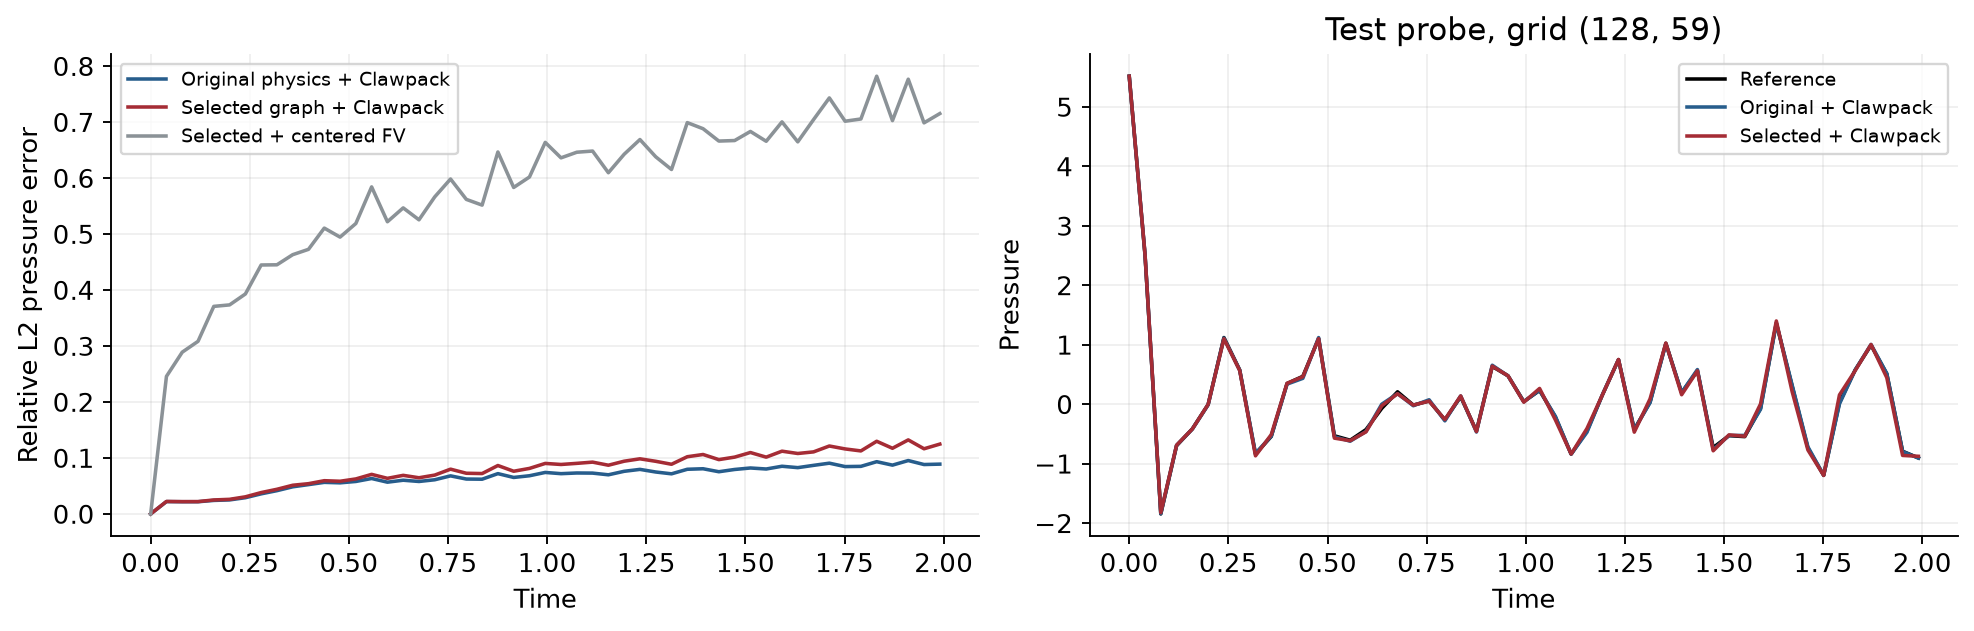

Fresh The Well pressure errors:


{'relative_L2': 0.06558091938495636,
 'final_relative_L2': 0.08894489705562592,
 'solver': 'Clawpack 5.9.0, unsplit MC, CFL 0.9'}

{'relative_L2': 0.08208406716585159,
 'final_relative_L2': 0.12471664696931839,
 'solver': 'Clawpack 5.9.0, unsplit MC, CFL 0.9'}

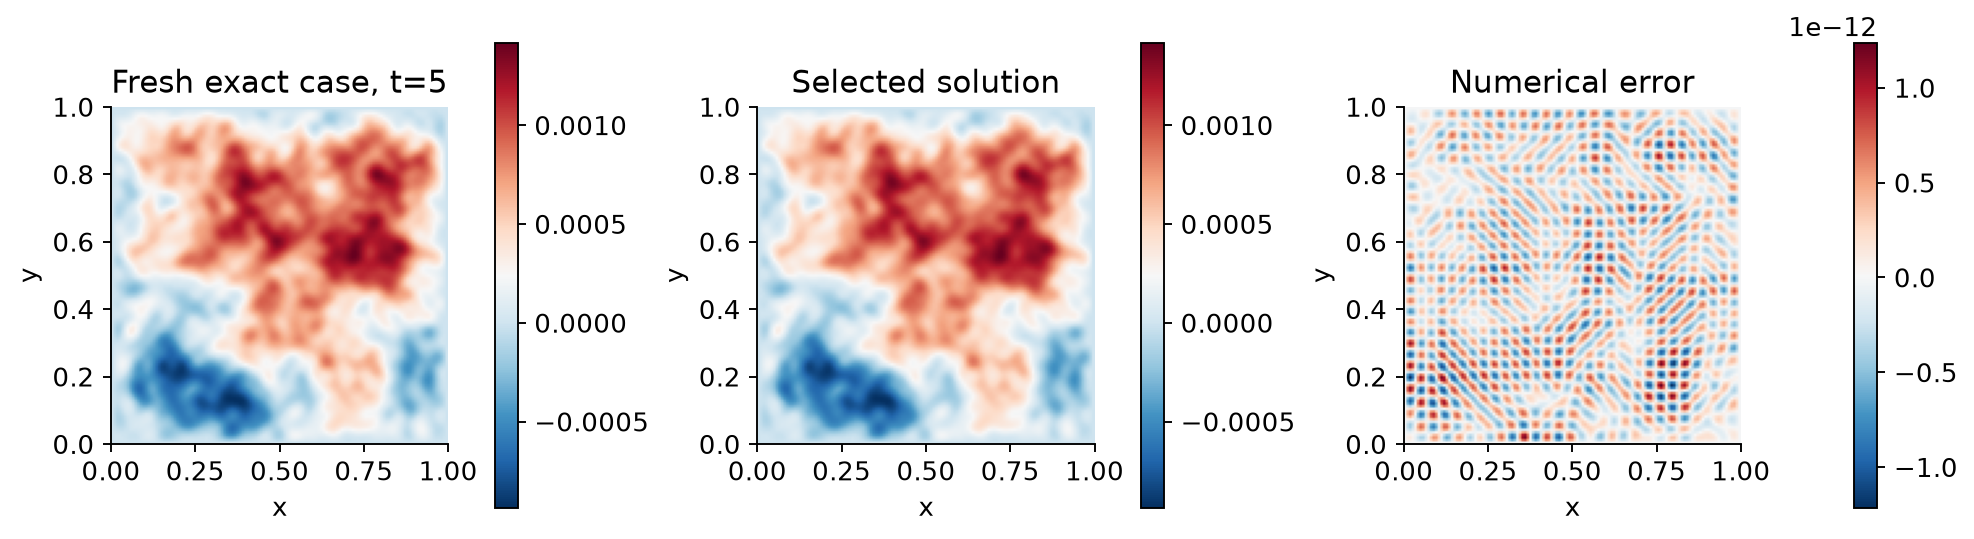

{'relative_L2': 3.3171184274513066e-10,
 'final_relative_L2': 5.629236888140858e-10,
 'steps': None,
 'solver': 'Sine-Galerkin + DOP853, rtol=1e-9'}

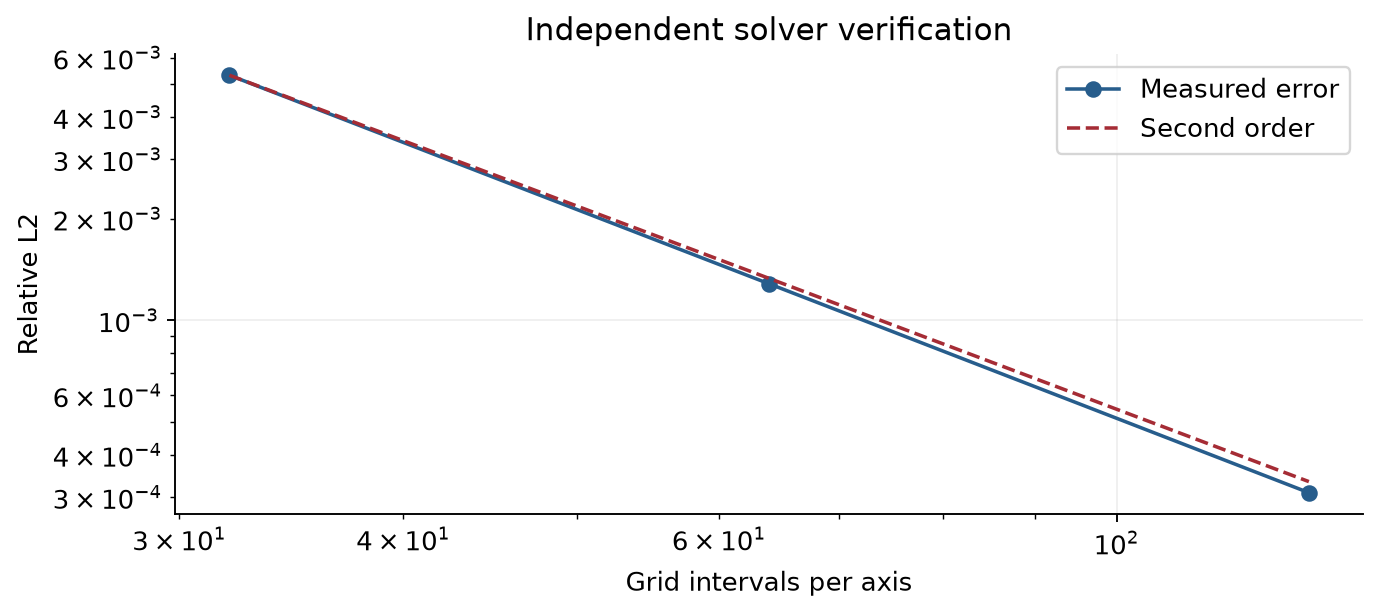

In [8]:
figure('well_data')
figure('well_approximation')
figure('well_error')
print('Fresh The Well pressure errors:')
display(report['well']['clawpack_original'])
display(report['well']['clawpack_selected'])
figure('analytic_approximation')
display(report['analytic']['selected_rollout'])
figure('convergence')


## 11. Три варианта критерия выбора

Во всех вариантах одинаковы данные версии 3, обученные коэффициенты и новый E_int.
Обозначим $Q=E_p+0.1E_m+0.5E_{int}$.

1. Текущий: $J_1=Q+0.02N+0.01B$, без статистического вето.
2. Без сложности: $J_2=Q+0.01B$, без статистического вето.
3. Без сложности + исходный фильтр: тот же $J_2$, но запрещено удалять ветви,
   которые исходная bootstrap-диагностика считает необходимыми. У допущенных B=0.

Математические и численные ограничения общие. Для парного сравнения совпадают
маски предложений, случайные U и температуры во всех трёх раундах.
Температуры берутся из базового варианта и больше не адаптируются отдельно.
Сложность не используется даже для разрешения точных равенств J: тогда берётся
меньший номер маски. Минимум сверяется с перебором, повторены 10 seed.

Общий test/sample_2 и seed 55002 уже просматривались: это постфактум-сравнение,
а не новый слепой тест. Коэффициенты и выбор графа не используют тестовые кадры.
На точной аналитике формально лишние ветви могут иметь коэффициенты порядка
1e-14 и быть практически эквивалентны исходному уравнению.

Подробный разбор: [отчёт о трёх критериях](criterion_comparison_report.md).

**well**

| Вариант | Маска | Ветвей | Допущено графов | Валидация | Перенос E_int | Общий тест |
|---|---:|---:|---:|---:|---:|---:|
| 1. Текущий | 3 | 2 | 16 | 8.37% | 7.78% | 8.21% |
| 2. Без сложности | 23 | 4 | 16 | 8.00% | 7.64% | 8.23% |
| 3. Без сложности + фильтр | 47 | 5 | 8 | 22.84% | 22.87% | 23.22% |

**analytic**

| Вариант | Маска | Ветвей | Допущено графов | Валидация | Перенос E_int | Общий тест |
|---|---:|---:|---:|---:|---:|---:|
| 1. Текущий | 3 | 2 | 16 | 6.686e-10 | 2.343e-10 | 3.317e-10 |
| 2. Без сложности | 43 | 4 | 16 | 6.686e-10 | 2.343e-10 | 3.317e-10 |
| 3. Без сложности + фильтр | 43 | 4 | 16 | 6.686e-10 | 2.343e-10 | 3.317e-10 |

**analytic_noise**

| Вариант | Маска | Ветвей | Допущено графов | Валидация | Перенос E_int | Общий тест |
|---|---:|---:|---:|---:|---:|---:|
| 1. Текущий | 3 | 2 | 16 | 1.639e-04 | 1.150e-04 | 1.300e-04 |
| 2. Без сложности | 7 | 3 | 16 | 2.789e-04 | 1.769e-04 | 2.133e-04 |
| 3. Без сложности + фильтр | 7 | 3 | 8 | 2.789e-04 | 1.769e-04 | 2.133e-04 |

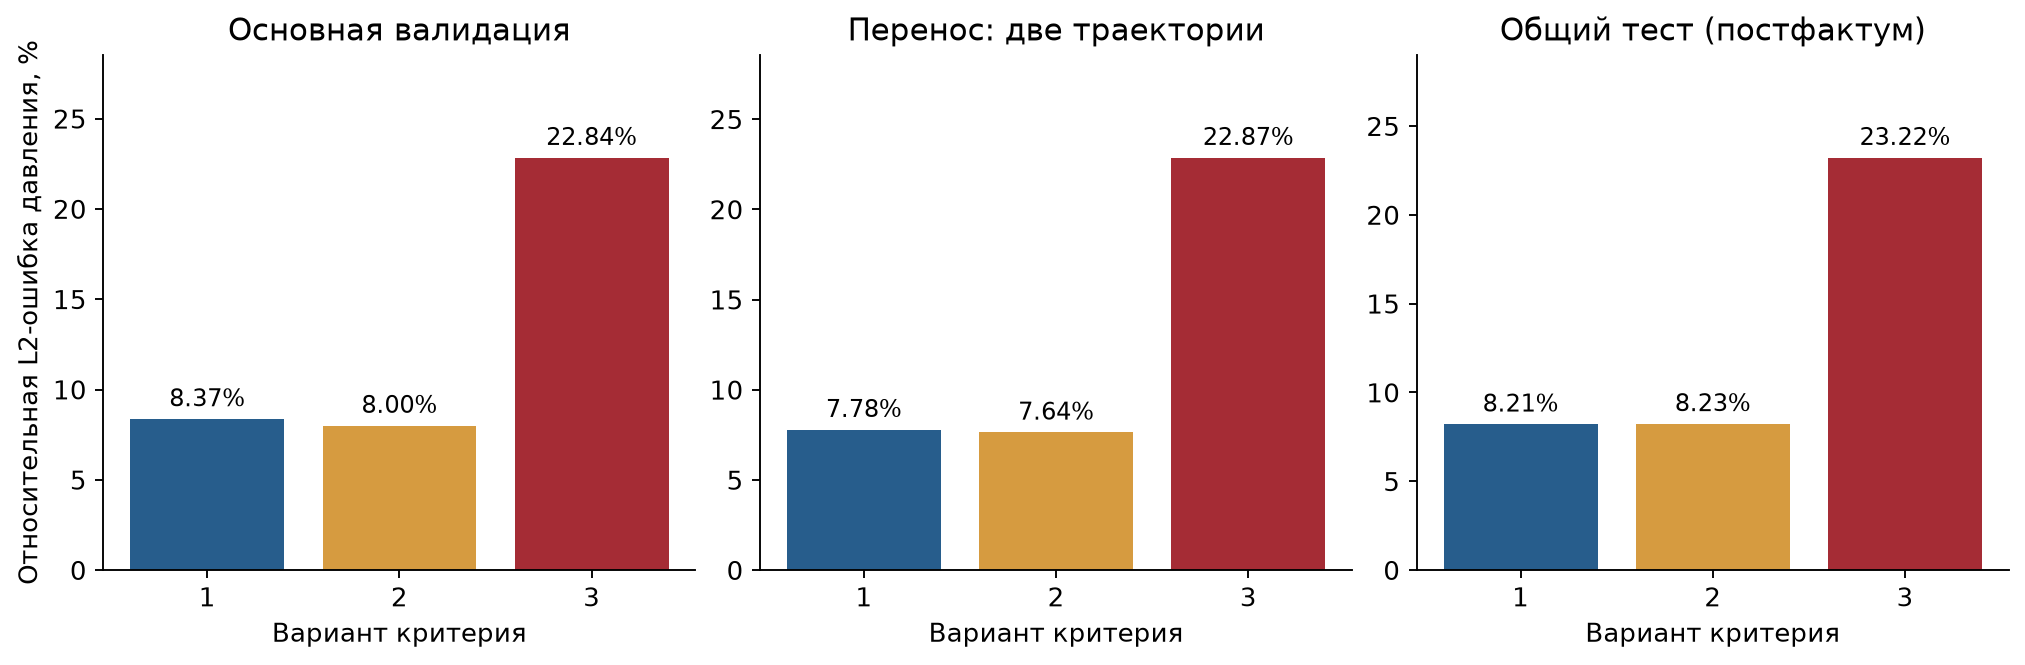

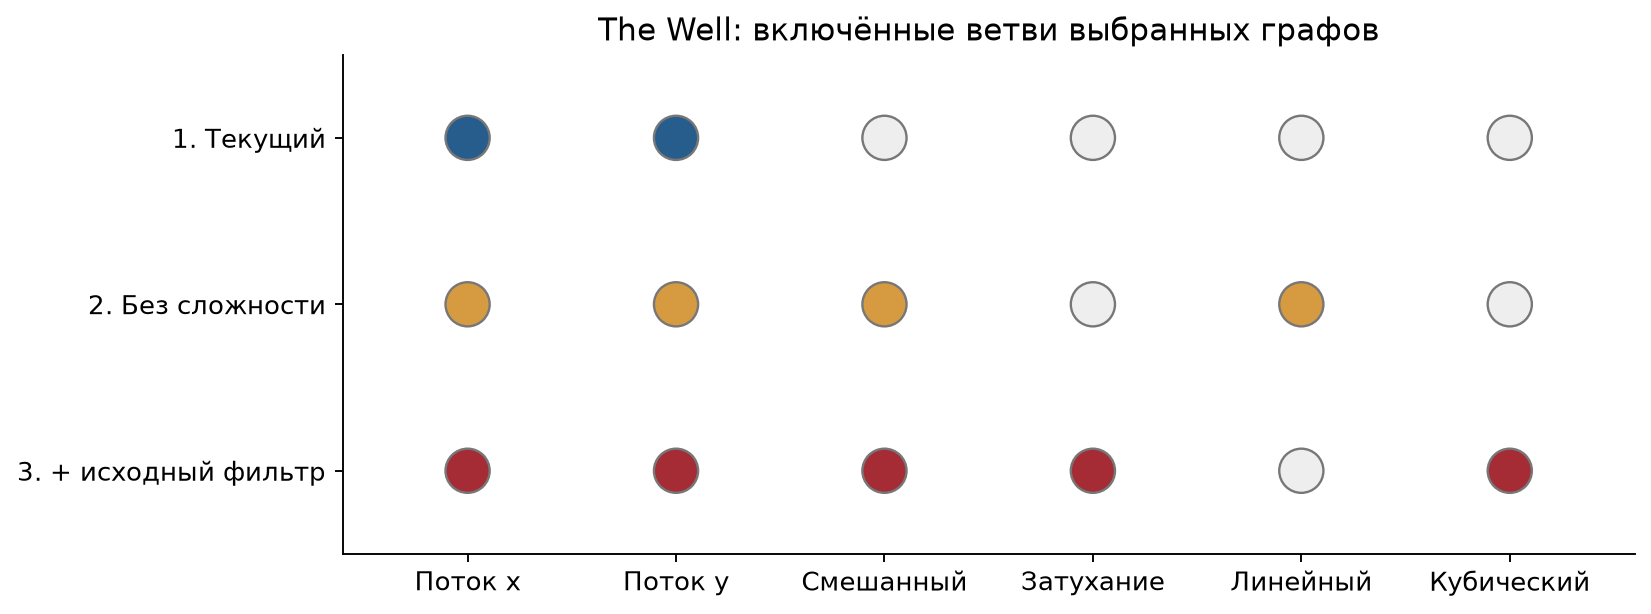

In [9]:
from IPython.display import Markdown
from lab03.criterion_comparison import run_comparison
from lab03.comparison_report import table
comparison=run_comparison()
for name in ('well','analytic','analytic_noise'):
    display(Markdown('**'+name+'**'))
    display(Markdown(table(comparison,name)))
figure('criterion_variants_errors')
figure('criterion_variants_branches')


## 12. Выводы и ограничения

Новая процедура сохраняет статистическую диагностику, но оценивает граф
по прямому решению на валидации. Исходная структура участвует в отборе;
в базовом варианте bootstrap-интервал не превращается в запрет. E_int использует отдельные
траектории; линейность и симметрия не используются для построения его эталонов.
Итоговый тест заменён, поскольку предыдущие траектории уже просматривались.

Вывод относится к заданной библиотеке и выбранным данным. По одной траектории
на часть недостаточно для общей оценки переноса между геометриями. Веса и
порог 50% — учебные решения. Проверка переноса охватывает только две дополнительные реализации; вычислительные
данные не являются физическими измерениями. Повторение seed семплера не
заменяет оценку неопределённости данных. Старые результаты не сравниваются
с новыми как единый тест — для сравнения критерия используется одна валидация.

Выбор двух пространственных членов относится к варианту со штрафом за N.
Без него The Well выбирает четыре ветви; с исходным жёстким фильтром — пять.
Это чувствительность к критерию, а не однозначное восстановление физики по данным.

## Источники и воспроизведение

- [The Well](https://polymathic-ai.org/the_well/datasets/acoustic_scattering_maze/),
  [данные и генератор](https://huggingface.co/datasets/polymathic-ai/acoustic_scattering_maze).
- [CNO/RPB](https://zenodo.org/records/10406879),
  [Raonić et al., C.3.2](https://arxiv.org/html/2302.01178v2#A3.SS3.SSS2).
- [Goodman: rejection sampling](https://math.nyu.edu/~goodman/teaching/MonteCarlo07/notes/SimpleSampling.pdf).
- [Clawpack](https://www.clawpack.org/gallery/pyclaw/gallery/acoustics_2d_interface.html).
- [Лабораторная № 2](../lab02/README.md), исходная работа Ф. Соболевского в `vendor/`.

Инструкции, происхождение данных и ограничения: [README](README.md), `sources.json`.
